# FibreEngine interface

The catalog lists analytical bases and numerical fibres. `catalog.specs` checks the inputs and returns the object passed to `FibreEngine`. Each example keeps its numbers at the top of the cell: edit them and run the cell again.

Run the setup cell first. `LG` and `HG` are analytical. `step_index`, `graded_index`, and `double_clad` are numerical, with `solver` set to `radial` or `scalar`.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb

_start = Path.cwd().resolve()
for _folder in (_start, *_start.parents):
    if (_folder / "fibremodes" / "catalog" / "registry.py").is_file():
        _algorithms = _folder
        break
    if _folder.name == "fibremodes" and (_folder / "catalog" / "registry.py").is_file():
        _algorithms = _folder.parent
        break
    if (_folder / "algorithms" / "fibremodes" / "catalog" / "registry.py").is_file():
        _algorithms = _folder / "algorithms"
        break
else:
    raise RuntimeError("Could not find the fibremodes package from the notebook working directory.")
if str(_algorithms) not in sys.path:
    sys.path.insert(0, str(_algorithms))

from fibremodes import FibreEngine, catalog


def show_schema(key):
    print(f"\n{key}")
    for param in catalog.schema(key):
        unit = param.unit or "-"
        exclusive = param.exclusive_group or "-"
        print(
            f"  {param.name:<16} {param.value_type.__name__:<6} unit={unit:<6} "
            f"required={str(param.required):<5} default={param.default!s:<6} exclusive={exclusive}"
        )


def summarize(result):
    print(f"{result.key}  modes={len(result.modes)}  fields={result.fields().shape}  unit={result.unit}")
    for mode in result.modes:
        n_eff = "-" if mode.n_eff is None else f"{mode.n_eff:.6f}"
        print(f"  {mode.label:<22} n_eff={n_eff:<10} indices={mode.indices}")


def complex_to_rgb(field):
    amplitude = np.abs(field)
    amplitude = amplitude / max(float(amplitude.max()), 1e-30)
    hue = (np.angle(field) + np.pi) / (2.0 * np.pi)
    hsv = np.stack([hue, np.ones_like(hue), amplitude], axis=-1)
    return hsv_to_rgb(hsv)


def show_modes(result, count=6):
    count = min(int(count), len(result.modes))
    if count == 0:
        print("No modes.")
        return
    scale = 1e6 if result.unit == "m" else 1.0
    unit_name = "um" if result.unit == "m" else (result.unit or "")
    fig, axes = plt.subplots(1, count, figsize=(2.8 * count, 3.0), squeeze=False)
    for ax, mode in zip(axes[0], result.modes[:count]):
        field = mode.field
        if result.x is None:
            extent = None
        else:
            edge = float(result.x[-1]) * scale
            extent = [-edge, edge, -edge, edge]
        if np.iscomplexobj(field):
            ax.imshow(complex_to_rgb(field), origin="lower", extent=extent)
        else:
            ax.imshow(np.abs(field), origin="lower", extent=extent, cmap="magma")
        title = mode.label if mode.n_eff is None else f"{mode.label}\nn_eff={mode.n_eff:.5f}"
        ax.set_title(title, fontsize=8)
        ax.set_xlabel(unit_name)
        ax.set_ylabel(unit_name)
    fig.tight_layout()
    plt.show()

## Catalog

`routes` is `analytical` or `numerical`. `list` is the entries on that route. `schema` is the inputs for one entry: name, type, unit, whether it is required, the default, and the exclusive group. Pass exactly one parameter from an exclusive group (`na` or `n_clad`, and the two double-clad pairs).

In [2]:
print("routes:", catalog.routes())
print("analytical:", catalog.list("analytical"))
print("numerical:", catalog.list("numerical"))
for key in ("LG", "HG", "step_index", "graded_index", "double_clad"):
    show_schema(key)

routes: ['analytical', 'numerical']
analytical: (CatalogEntry('LG', route='analytical'), CatalogEntry('HG', route='analytical'))
numerical: (CatalogEntry('step_index', route='numerical', solvers=('radial', 'scalar')), CatalogEntry('graded_index', route='numerical', solvers=('radial', 'scalar')), CatalogEntry('double_clad', route='numerical', solvers=('radial', 'scalar')))

LG
  mfd              float  unit=pixel  required=True  default=None   exclusive=-
  group            int    unit=-      required=True  default=None   exclusive=-
  N                int    unit=-      required=True  default=None   exclusive=-
  px_size          float  unit=pixel  required=True  default=None   exclusive=-
  wholeSet         bool   unit=-      required=False default=False  exclusive=-
  farfield         bool   unit=-      required=False default=False  exclusive=-
  engine           str    unit=-      required=False default=GPU    exclusive=-
  multicore        bool   unit=-      required=False default=

## HG

`mfd` is the fundamental mode-field diameter in pixels. The engine passes waist `mfd / 2` to the Hermite-Gaussian generator. `group` mode groups produce `group * (group + 1) / 2` modes.

HG  modes=10  fields=(10, 128, 128)  unit=pixel
  HG m=0, n=0            n_eff=-          indices={'m': 0, 'n': 0, 'group': 0}
  HG m=0, n=1            n_eff=-          indices={'m': 0, 'n': 1, 'group': 1}
  HG m=1, n=0            n_eff=-          indices={'m': 1, 'n': 0, 'group': 1}
  HG m=0, n=2            n_eff=-          indices={'m': 0, 'n': 2, 'group': 2}
  HG m=1, n=1            n_eff=-          indices={'m': 1, 'n': 1, 'group': 2}
  HG m=2, n=0            n_eff=-          indices={'m': 2, 'n': 0, 'group': 2}
  HG m=0, n=3            n_eff=-          indices={'m': 0, 'n': 3, 'group': 3}
  HG m=1, n=2            n_eff=-          indices={'m': 1, 'n': 2, 'group': 3}
  HG m=2, n=1            n_eff=-          indices={'m': 2, 'n': 1, 'group': 3}
  HG m=3, n=0            n_eff=-          indices={'m': 3, 'n': 0, 'group': 3}


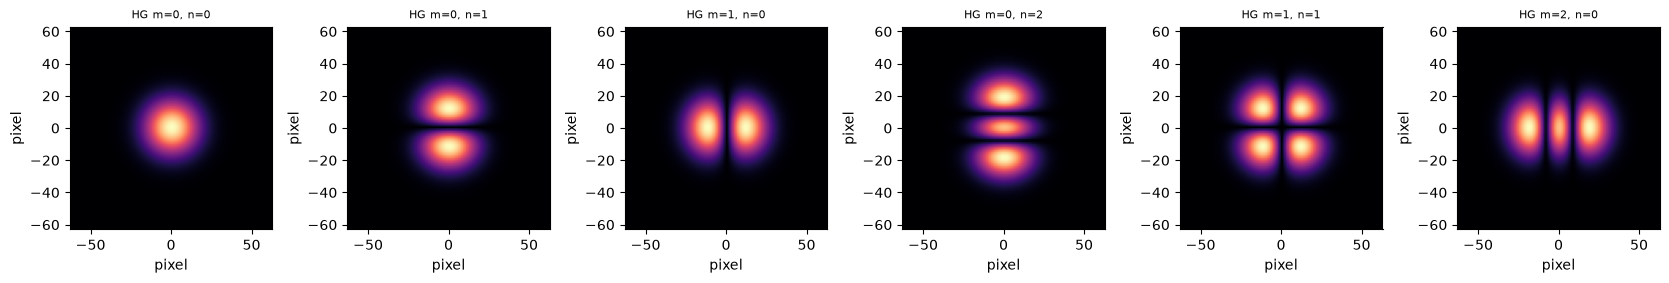

In [3]:
mfd = 34
group = 4
N = 128

specs = catalog.specs("HG", mfd=mfd, group=group, N=N)
hg = FibreEngine(specs).solve()
summarize(hg)
show_modes(hg)

## LG

`engine="CPU"` avoids the GPU path. `multicore=False` uses the single-core CPU evaluator; set it to `True` when `ipyparallel` is available. `wholeSet=True` inserts the complex conjugate immediately after each mode whose azimuthal index is not zero, labeled with `-l`. `mfd` and `px_size` use the same length unit; with `px_size=1` that unit is the pixel.

Generating modes coeficients...
Generating modes...
Engine : CPU singlecore
Generating rest of the modes...
LG  modes=10  fields=(10, 128, 128)  unit=pixel
  LG p=0, l=0            n_eff=-          indices={'p': 0, 'l': 0}
  LG p=0, l=1            n_eff=-          indices={'p': 0, 'l': 1}
  LG p=0, l=-1           n_eff=-          indices={'p': 0, 'l': -1}
  LG p=0, l=2            n_eff=-          indices={'p': 0, 'l': 2}
  LG p=0, l=-2           n_eff=-          indices={'p': 0, 'l': -2}
  LG p=1, l=0            n_eff=-          indices={'p': 1, 'l': 0}
  LG p=0, l=3            n_eff=-          indices={'p': 0, 'l': 3}
  LG p=0, l=-3           n_eff=-          indices={'p': 0, 'l': -3}
  LG p=1, l=1            n_eff=-          indices={'p': 1, 'l': 1}
  LG p=1, l=-1           n_eff=-          indices={'p': 1, 'l': -1}


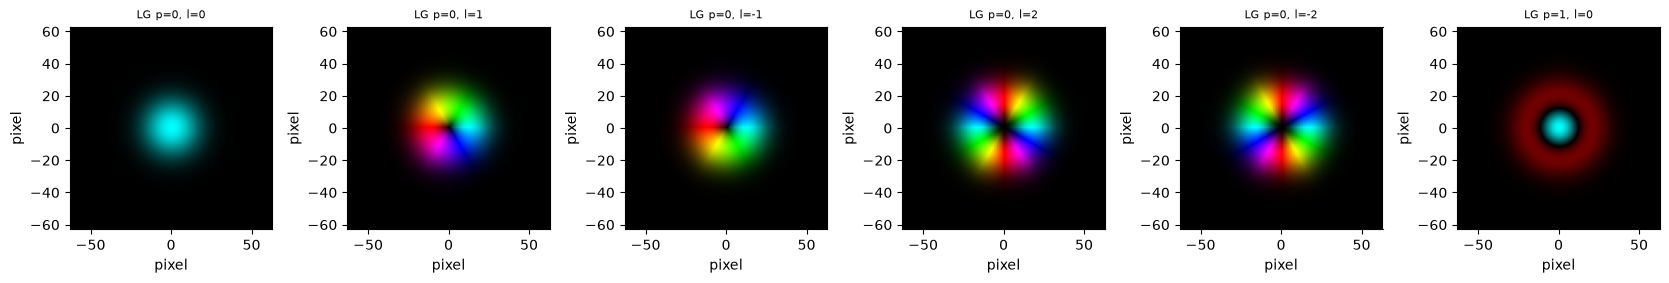

In [4]:
mfd = 34
group = 4
N = 128
px_size = 1
engine = "CPU"
wholeSet = True
multicore = False

specs = catalog.specs(
    "LG", mfd=mfd, group=group, N=N, px_size=px_size,
    engine=engine, wholeSet=wholeSet, multicore=multicore,
)
lg = FibreEngine(specs).solve()
summarize(lg)
show_modes(lg)

## Step index

The same fibre is solved twice. The radial solver stops at the first azimuthal order with no guided eigenvalues. The scalar solver uses the Cartesian index. `n_samples` is the solver grid. `grid_n` is the plotted field. Lengths are metres.

step_index  modes=5  fields=(5, 64, 64)  unit=m
  L=0, M=1               n_eff=1.448811   indices={'L': 0, 'M': 1, 'mode_group': 1}
  L=-1, M=1              n_eff=1.447079   indices={'L': -1, 'M': 1, 'mode_group': 2}
  L=1, M=1               n_eff=1.447079   indices={'L': 1, 'M': 1, 'mode_group': 2}
  L=-2, M=1              n_eff=1.445045   indices={'L': -2, 'M': 1, 'mode_group': 3}
  L=2, M=1               n_eff=1.445045   indices={'L': 2, 'M': 1, 'mode_group': 3}


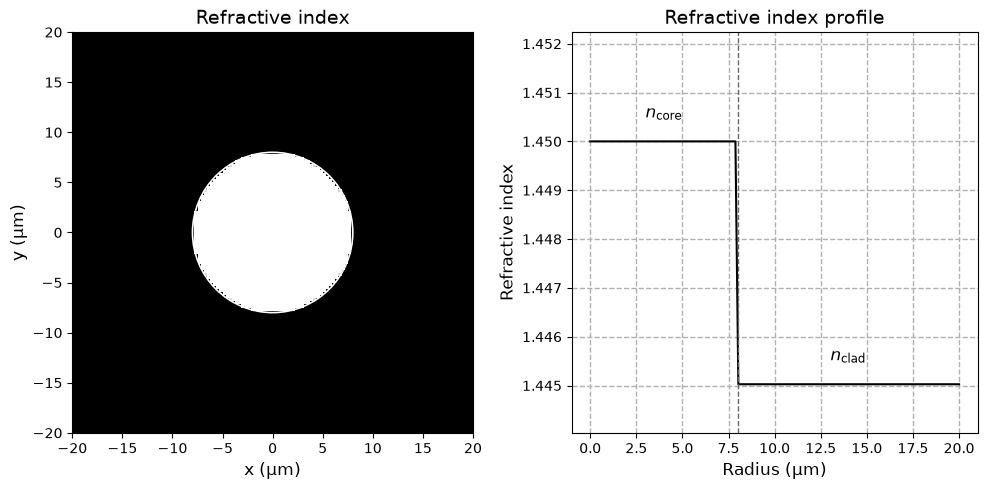

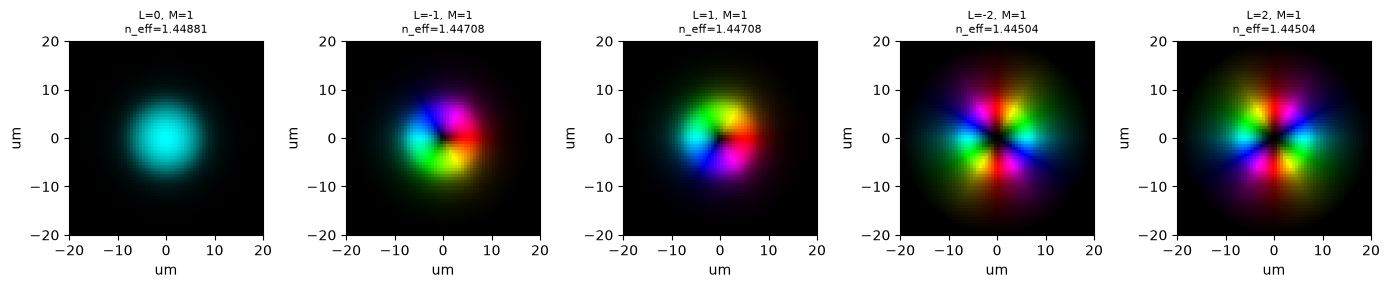

In [4]:
core_radius = 8e-6
r_max = 20e-6
n_core = 1.45
na = 0.12
wavelength = 1550e-9
n_samples = 128
grid_n = 64

specs = catalog.specs(
    "step_index", solver="radial",
    core_radius=core_radius, r_max=r_max, n_core=n_core, na=na,
    wavelength=wavelength, n_samples=n_samples, grid_n=grid_n,
)
step_radial = FibreEngine(specs).solve()
step_radial.profile.plot()
summarize(step_radial)
show_modes(step_radial)

In [5]:
res_step = step_radial.resample(400)

In [7]:
step_radial.get_fields_resample().shape

(5, 400, 400)

In [ ]:
core_radius = 8e-6
r_max = 20e-6
n_core = 1.45
na = 0.12
wavelength = 1550e-9
n_samples = 128
grid_n = 64

specs = catalog.specs(
    "step_index", solver="scalar",
    core_radius=core_radius, r_max=r_max, n_core=n_core, na=na,
    wavelength=wavelength, n_samples=n_samples, grid_n=grid_n,
)
step_scalar = FibreEngine(specs).solve()
summarize(step_scalar)
show_modes(step_scalar)

## Graded index

`alpha=2` is the parabolic profile. The radial solver keeps every guided azimuthal order.

In [ ]:
core_radius = 12e-6
r_max = 24e-6
n_core = 1.46
na = 0.15
alpha = 2.0
wavelength = 1550e-9
n_samples = 128
grid_n = 64

specs = catalog.specs(
    "graded_index", solver="radial",
    core_radius=core_radius, r_max=r_max, n_core=n_core, na=na, alpha=alpha,
    wavelength=wavelength, n_samples=n_samples, grid_n=grid_n,
)
graded = FibreEngine(specs).solve()
graded.profile.plot()
summarize(graded)
show_modes(graded)

## Double clad

Pass `na_core` or `n_clad1`, and `na_clad1` or `n_clad2`. The last cell passes both core descriptions so the catalog rejects the spec before any solve.

double_clad  modes=13  fields=(13, 64, 64)  unit=m
  L=0, M=1               n_eff=1.447487   indices={'L': 0, 'M': 1, 'mode_group': 1}
  L=-1, M=1              n_eff=1.445191   indices={'L': -1, 'M': 1, 'mode_group': 2}
  L=1, M=1               n_eff=1.445191   indices={'L': 1, 'M': 1, 'mode_group': 2}
  L=-2, M=1              n_eff=1.443495   indices={'L': -2, 'M': 1, 'mode_group': 3}
  L=0, M=2               n_eff=1.443958   indices={'L': 0, 'M': 2, 'mode_group': 3}
  L=2, M=1               n_eff=1.443495   indices={'L': 2, 'M': 1, 'mode_group': 3}
  L=-1, M=2              n_eff=1.441771   indices={'L': -1, 'M': 2, 'mode_group': 4}
  L=1, M=2               n_eff=1.441771   indices={'L': 1, 'M': 2, 'mode_group': 4}
  L=-2, M=2              n_eff=1.438737   indices={'L': -2, 'M': 2, 'mode_group': 5}
  L=0, M=3               n_eff=1.438644   indices={'L': 0, 'M': 3, 'mode_group': 5}
  L=2, M=2               n_eff=1.438737   indices={'L': 2, 'M': 2, 'mode_group': 5}
  L=-1, M=3          

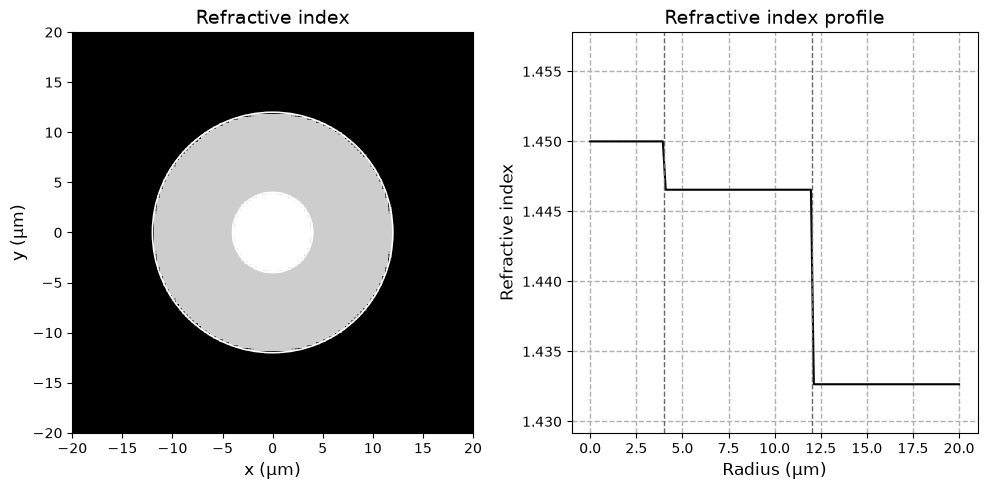

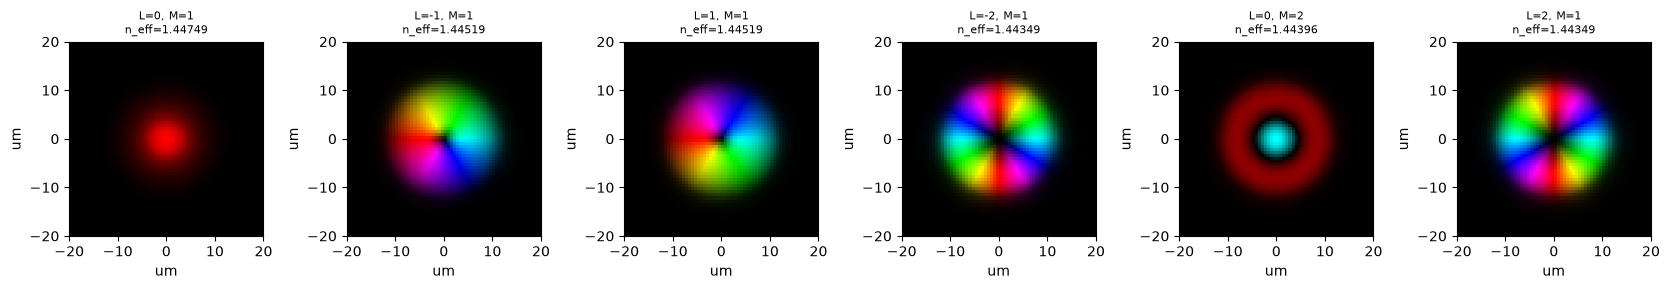

In [3]:
core_radius = 4e-6 / 2
clad1_radius = 23e-6 / 2
r_max = clad1_radius * 2
n_core = 1.45841
na_core = 0.13
na_clad1 = 0.20
wavelength = 843.5e-9
n_samples = 512
grid_n = 64

specs = catalog.specs(
    "double_clad", solver="radial",
    core_radius=core_radius, clad1_radius=clad1_radius, r_max=r_max, n_core=n_core,
    na_core=na_core, na_clad1=na_clad1,
    wavelength=wavelength, n_samples=n_samples, grid_n=grid_n,
)
double_clad = FibreEngine(specs).solve()
double_clad.profile.plot()
summarize(double_clad)
show_modes(double_clad)

In [ ]:
try:
    catalog.specs(
        "double_clad", solver="radial",
        core_radius=4e-6, clad1_radius=12e-6, r_max=20e-6, n_core=1.45,
        na_core=0.10, n_clad1=1.44, na_clad1=0.20,
        wavelength=1550e-9, n_samples=128, grid_n=64,
    )
except ValueError as error:
    print(error)